# An introduction to the DC-emulator

This notebook is a short tutorial on using the DC-emulator to super-resolve N-body simulations. The model takes a low-resolution (LR) snapshot and predicts the displacement and velocity fields of a simulation with 2x the resolution per dimension (8x the particles), conditioned on the cosmology.

**What you need**
- The trained weights (see the README for where to download them).
- A low-resolution Gadget snapshot of CDM particles on an $N^3$ grid (256³ in this example).
- The unperturbed initial conditions for the same simulation (particles on the Lagrangian lattice).
- The value of $\sigma_8$ used in the simulation (it is not stored in the Gadget header).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from src import DCEmulator
from src.utils import dis2pos
from src.analysis import mass_assignment, power   # requires Pylians

### Setting up the model

`DCEmulator` loads the trained weights from `dc_emulator_weights.pt` in the repository root (pass `state_path=...` if you keep them somewhere else). By default it runs on a GPU if one is available and otherwise on the CPU; you can also pass `device="cpu"` or `device="cuda"` explicitly. Upscaling a 256³ box takes a few minutes on a CPU.

`seed` sets the fixed noise realisation used by `noise="fixed"` and by `velocity` (see below), which makes results reproducible.

In [2]:
model = DCEmulator(seed=42)
print("Running on", model.device)

dz = 1e-5           # half-width of the redshift step used for the velocity finite difference

sigma8 = 0.778      # sigma_8 of the simulation
BoxSize = 1000.     # Mpc/h
Ngrid_LR = 256
Ngrid_SR = 2 * Ngrid_LR

Running on cpu


### Generating fields 

`position` and `velocity` read a snapshot and return its displacement and velocity fields on the Lagrangian grid, with shape `[3, N, N, N]`. The unperturbed initial conditions give the Lagrangian positions $\bf{q}$ in

$$
\bf{x} = \bf{q} + \psi
$$

where $\psi$ is the displacement (in Mpc/h). The other cosmological parameters ($a$, $\Omega_m$, $\Omega_\Lambda$, $h$) are read from the snapshot header.

The velocity is computed with a central finite difference in time,
$$
\bf{v} = a \frac{d\bf{x}}{dt} \approx a \frac{\bf{x}(t + \Delta t) - \bf{x}(t - \Delta t)}{2 \Delta t},
$$
where the particles are drifted by $\pm dz$ in redshift (or $\pm da$ in scale factor) using their snapshot velocities.

With `upscale=False` you get the low-resolution fields straight from the snapshot:

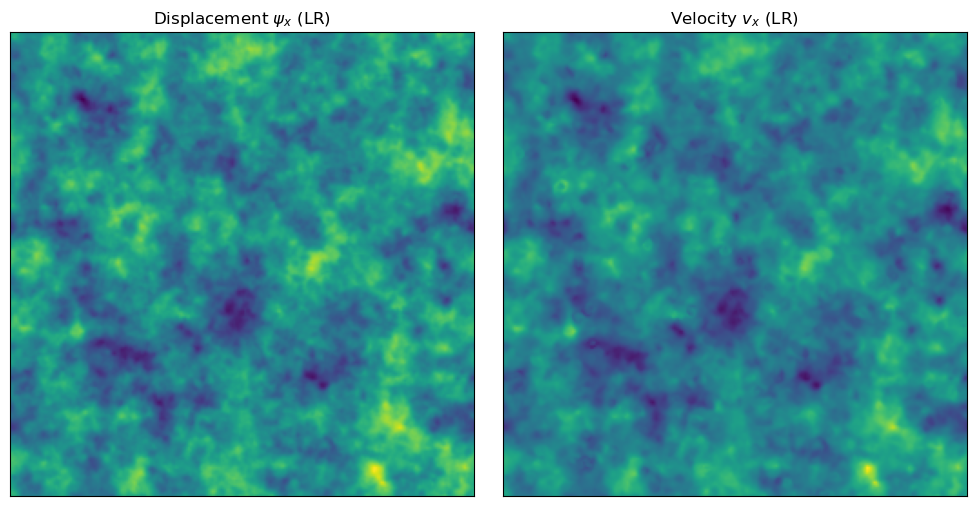

In [3]:
# Low-resolution snapshot to upscale, and the unperturbed initial conditions.
# Replace these paths with your own files.
file = "/mn/stornext/d8/data/dennisfr/DCGAN/data/node8/su_snap009_cdm"
file_q = "/mn/stornext/d8/data/dennisfr/DCDATA/node0/gevolution/ics.0"

# Velocity field
vel_LR = model.velocity(file, file_q, sigma8=sigma8, dz=dz, upscale=False)

# Displacement field, converted to particle positions of shape [N^3, 3]
dis_LR = model.position(file, file_q, sigma8=sigma8, upscale=False)
pos_LR = dis2pos(dis_LR, BoxSize, Ngrid_LR).reshape((3, Ngrid_LR**3)).T

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].imshow(dis_LR[0, 0])
ax[0].set_title(r"Displacement $\psi_x$ (LR)")

ax[1].imshow(vel_LR[0, 0])
ax[1].set_title(r"Velocity $v_x$ (LR)")

for axi in ax:
    axi.set_xticks([]); axi.set_yticks([])

plt.tight_layout()

### Upscaling a snapshot

To super-resolve the snapshot, call the same methods with `upscale=True`. The output has shape `[3, 2N, 2N, 2N]`.

The generator injects random noise to create small-scale structure, so the `noise` argument of `position` controls which realisation you get:
- `noise=None` (default): a new random realisation on every call.
- `noise="fixed"`: the model's fixed realisation (set by `seed`), so repeated calls give identical results.

`velocity` always uses the fixed realisation for both time steps, so the finite difference reflects how the field moves rather than a change in noise.

The upscaling below runs the network on a full 256³ box three times (twice for the velocity, once for the position), so it takes a while on a CPU.

16/64 chunks done
32/64 chunks done
48/64 chunks done
64/64 chunks done
16/64 chunks done
32/64 chunks done
48/64 chunks done
64/64 chunks done
16/64 chunks done
32/64 chunks done
48/64 chunks done
64/64 chunks done


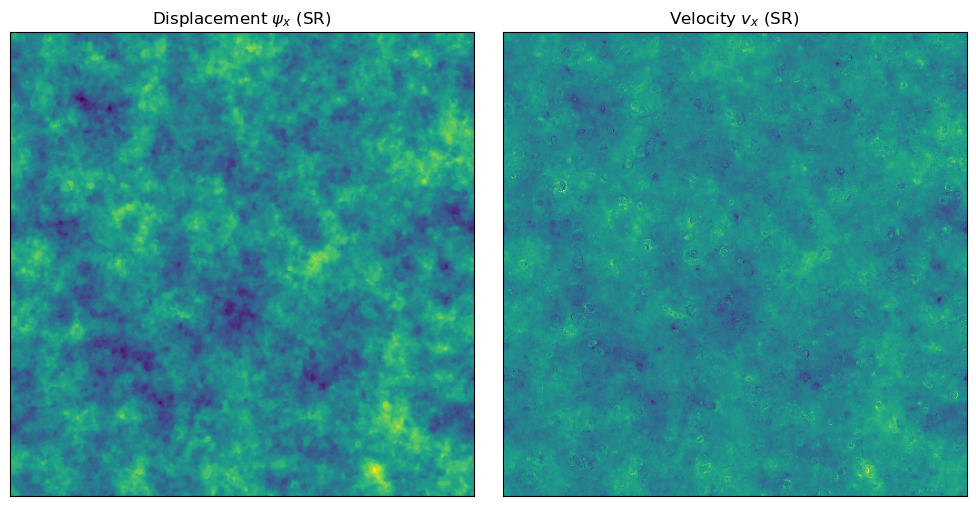

In [4]:
# Velocity field
vel_SR = model.velocity(file, file_q, sigma8=sigma8, dz=dz, upscale=True)

# Displacement field, converted to particle positions of shape [(2N)^3, 3]
dis_SR = model.position(file, file_q, sigma8=sigma8, upscale=True, noise="fixed")
pos_SR = dis2pos(dis_SR, BoxSize, Ngrid_SR).reshape((3, Ngrid_SR**3)).T

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].imshow(dis_SR[0, 0])
ax[0].set_title(r"Displacement $\psi_x$ (SR)")

ax[1].imshow(vel_SR[0, 0])
ax[1].set_title(r"Velocity $v_x$ (SR)")

for axi in ax:
    axi.set_xticks([]); axi.set_yticks([])

plt.tight_layout()

### Comparing the density fields

The displacement fields are hard to interpret by eye. Assigning the particles to a grid gives the density field, and its power spectrum shows how much small-scale power the model adds. Each field is painted onto a grid with one cell per particle (256³ for LR, 512³ for SR).


Computing power spectrum of the field...
Time to complete loop = 0.57
Time taken = 0.64 seconds

Computing power spectrum of the field...
Time to complete loop = 4.55
Time taken = 5.01 seconds


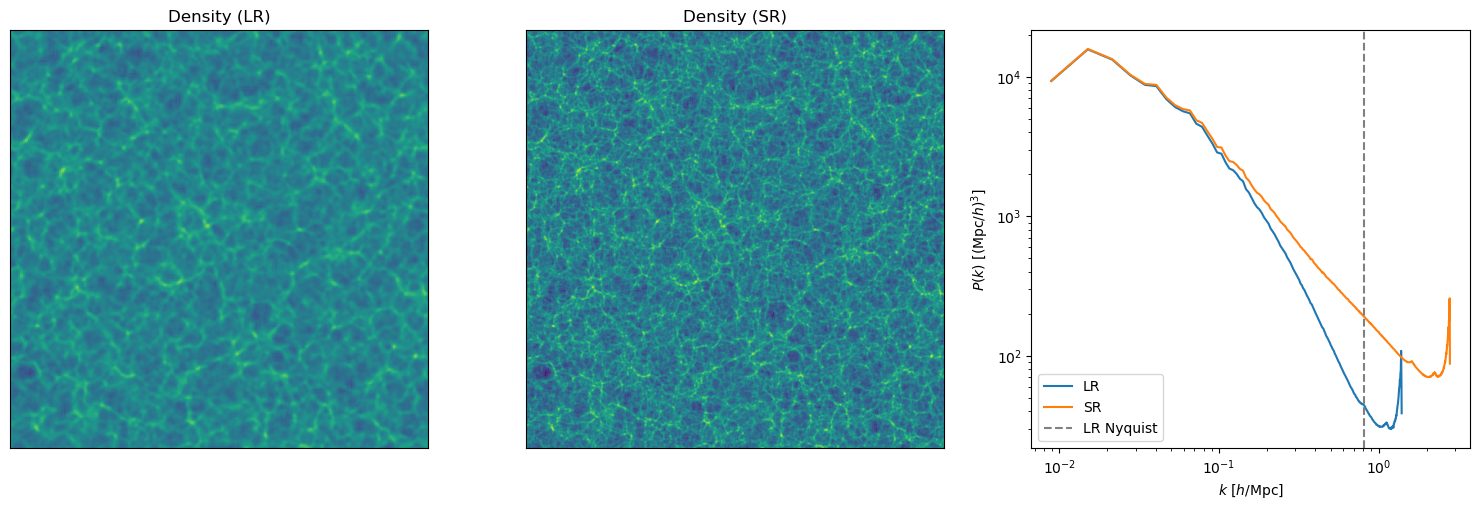

In [5]:
# Density contrast 1 + delta on grids with one cell per particle
rho_LR = mass_assignment(dis_LR, Ngrid_LR, BoxSize, verbose=False)
rho_SR = mass_assignment(dis_SR, Ngrid_SR, BoxSize, verbose=False)

k_LR, Pk_LR = power(rho_LR - 1, BoxSize)
k_SR, Pk_SR = power(rho_SR - 1, BoxSize)

# Projected density in a ~16 Mpc/h thick slab
slab = 16.
proj_LR = rho_LR[:int(slab / BoxSize * Ngrid_LR)].mean(axis=0)
proj_SR = rho_SR[:int(slab / BoxSize * Ngrid_SR)].mean(axis=0)

fig, ax = plt.subplots(ncols=3, figsize=(15, 5))

vmin, vmax = np.log10(proj_SR).min(), np.log10(proj_SR).max()
ax[0].imshow(np.log10(proj_LR), vmin=vmin, vmax=vmax)
ax[0].set_title("Density (LR)")
ax[1].imshow(np.log10(proj_SR), vmin=vmin, vmax=vmax)
ax[1].set_title("Density (SR)")
for axi in ax[:2]:
    axi.set_xticks([]); axi.set_yticks([])

ax[2].loglog(k_LR, Pk_LR, label="LR")
ax[2].loglog(k_SR, Pk_SR, label="SR")
ax[2].axvline(np.pi * Ngrid_LR / BoxSize, color="gray", ls="--", label="LR Nyquist")
ax[2].set_xlabel(r"$k$ [$h$/Mpc]")
ax[2].set_ylabel(r"$P(k)$ [(Mpc/$h$)$^3$]")
ax[2].legend()

plt.tight_layout()

### Upscaling a displacement field directly

If your displacement field doesn't come from a Gadget snapshot, call `upscale` with a `[3, N, N, N]` array in Mpc/h, ordered on the Lagrangian lattice. Give the cosmology as keyword arguments (`z` can be used instead of `a`) or as a style vector `s = [a, Om_k, sigma8, Om_m, h]`. `N` must be divisible by `model.nsplit` (4 by default).

In [6]:
import readgadget

header = readgadget.header(file)
Om_m, Om_l = header.omega_m, header.omega_l

dis_SR2 = model.upscale(
    dis_LR,
    a=header.time, Om_k=1 - Om_m - Om_l, sigma8=sigma8, Om_m=Om_m, h=header.hubble,
    noise="fixed",
)

# Same input, cosmology and noise realisation as `position` above, so the result is identical
print(dis_SR2.shape, np.allclose(dis_SR2, dis_SR))

16/64 chunks done
32/64 chunks done
48/64 chunks done
64/64 chunks done
(3, 512, 512, 512) True
